In [1]:
from openai import OpenAI
import os
import docx
import pdfplumber
import subprocess

from langchain_openai import ChatOpenAI
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode

from langsmith import traceable

In [2]:
os.environ["LANGSMITH_TRACING"] = "false"
#os.environ["LANGSMITH_API_KEY"] = "YOUR API KEY HERE" ### just delete the # in this line ###
os.environ["LANGSMITH_PROJECT"] = "project 1"
os.environ["LANGSMITH_ENDPOINT"] = "https://eu.api.smith.langchain.com"

In [3]:
#os.environ["OPENAI_API_KEY"] = "YOUR API KEY HERE" ### just delete the # in this line ###
#client = OpenAI(api_key=os.getenv("OPENAI_API_KEY")) ### just delete the # in this line ###

In [4]:
llm = ChatOpenAI(model="gpt-4.1")

In [5]:

def job_posting_tool(job_link: str) -> str:
    """
    Visit a job posting and extract its key details.
    """

    completion = client.responses.create(
        model="gpt-4.1",
        tools=[
            {
                "type": "web_search",
                "search_context_size": "medium",
            }
        ],
        input=f"""
        You are a helpful tool that visits the following job posting and carefully read its contents.

        Visit this job posting link, read it thoroughly, and extract and summarize all key information. Include:
        - Job title
        - Company name
        - Location
        - Employment type (full-time, part-time, contract, etc.)
        - Salary or compensation (if available)
        - Required qualifications/skills
        - Primary responsibilities
        - Benefits offered
        - Application instructions
        - Posting date (if available)

        Format
        - Respond with a clear, structured bullet-point list.
        - Use exact factual information from the posting, no rewording beyond making it concise.
        - If the posting is missing, inaccessible, or contains no job details, respond with:
        "Job posting unavailable or contains no job details."

        Do's
        - Ensure all extracted details are accurate and directly taken from the posting.
        - Keep descriptions short, professional, and easy to scan.
        - Use consistent formatting for all fields (e.g., "Job Title: ...").

        Don'ts
        - Do not include filler language, speculation, or personal opinions.
        - Do not rewrite or interpret details—only report factual information from the posting.

        Visit this job posting and extract details:
        {job_link}
        """
    )

    return completion.output_text


In [6]:
@tool
def extract_cv_text(file_path: str) -> str:
    """Extracts the text content from a CV file in PDF, DOCX, or DOC format. The CV should be inside the same folder that this notebook is in.

    Args:
        file_path (str): The local file path to the CV document. 

    Returns:
        str: The extracted plain text from the CV, or an error message if the format is unsupported or cannot be read.
    """
    
    ext = os.path.splitext(file_path)[-1].lower()
    
    if ".docx" in ext:
        try:
            doc = docx.Document(file_path)
            text = [para.text for para in doc.paragraphs]
            return '\n'.join(text)
        except Exception as e:
            return f"Error reading the .docx file: {e}"
        
    elif ".pdf" in ext:
        try:
            text = []
            with pdfplumber.open(file_path) as pdf:
                for page in pdf.pages:
                    page_text = page.extract_text()
                    if page_text:
                        text.append(page_text)
            return '\n'.join(text)
        except Exception as e:
            return f"Error reading the .pdf file: {e}"
    
    elif ".doc" in ext:
        try:
            temp_docx = file_path + ".temp.docx"
            subprocess.run(['soffice', '--headless', '--convert-to', 'docx', '--outdir', os.path.dirname(file_path), file_path], check=True)
            
            doc = docx.Document(os.path.splitext(file_path)[0] + ".docx")
            text = [para.text for para in doc.paragraphs]
            
            os.remove(os.path.splitext(file_path)[0] + ".docx")
            return '\n'.join(text)
        except Exception as e:
            return f"Error reading .doc file: {e}"
    
    else:
        return "Unsupported file format. Please use .pdf, .docx, or .doc."

In [7]:
tools = [job_posting_tool, extract_cv_text]
tool_node = ToolNode(tools=tools)

In [8]:
llm_with_tools = llm.bind_tools(tools)

In [9]:
from langgraph.graph import MessagesState
from langchain_core.messages import HumanMessage, SystemMessage

sys_msg = SystemMessage(content="""
You are an expert career assistant that helps the user with questions related to jobs, careers, and applications.

Your key capabilities:
- You have access to the user's CV and can read its contents using the `extract_cv_text` tool.
- You can look up and extract details from job postings using the `job_posting_tool`.
- You can compare the user's CV against one or more job postings to determine suitability and provide tailored advice.
- You can suggest improvements to the CV for better alignment with target roles.

When answering:
1. First, think step-by-step about the user's request.
2. If the task requires reading the CV, call the CV extraction tool before answering.
3. If the task involves evaluating job postings, call the job posting tool to gather accurate information before answering.
4. Compare and reason about the information before providing your final response.

Response format:
- Be clear, concise, and structured with bullet points or numbered lists.
- Use section headers when possible (e.g., "Strengths", "Weaknesses", "Recommendations").
- Support your statements with evidence from the CV or job postings.
- Avoid vague language—be specific and factual.

Constraints:
- Do not invent or guess details about the user's experience or job postings.
- Only use information available in the CV, job postings, or provided context.
- Keep your tone professional, friendly, and supportive.


""")

In [10]:
@traceable(name="Job Posting Tool")
def assistant(state: MessagesState):
   return {"messages": [llm_with_tools.invoke([sys_msg] + state["messages"])]}

In [11]:
from langgraph.graph import START, StateGraph
from langgraph.prebuilt import tools_condition
from IPython.display import Image, display

builder = StateGraph(MessagesState)

builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", tools_condition)

builder.add_edge("tools", "assistant")
react_graph = builder.compile()


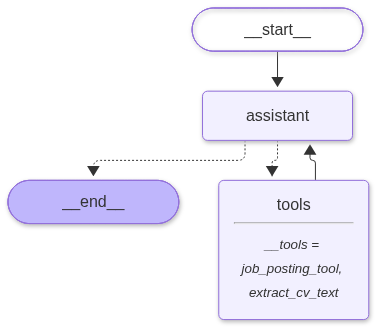

In [12]:
display(Image(react_graph.get_graph(xray=True).draw_mermaid_png()))

In [13]:
from langgraph.checkpoint.memory import MemorySaver
memory = MemorySaver()
react_graph_memory = builder.compile(checkpointer=memory)

In [14]:
config = {"configurable": {"thread_id": "1"}}

In [15]:
messages = [HumanMessage(content="""
        Can you take a look at my CV ath the location 'cv-template2.pdf'  and these 3 job applications and tell me whichone is the most suitable for my expiriance: 
        
        'https://www.indeed.com/viewjob?jk=247e94f9a28c544f&tk=1isdf5na1h72t810&from=serp&vjs=3',
        'https://www.indeed.com/viewjob?jk=744686732444f370&tk=1isns1midj72r8b4&from=serp&vjs=3',
        'https://www.indeed.com/viewjob?jk=01e2f371f220e42a&tk=1isns1midj72r8b4&from=serp&vjs=3'
        
        """)]

In [16]:
result = react_graph_memory.invoke({"messages": messages}, config)

In [17]:
for m in result['messages']:
    m.pretty_print()

================================ Human Message =================================


        Can you take a look at my CV ath the location 'cv-template2.pdf'  and these 3 job applications and tell me whichone is the most suitable for my expiriance: 

        'https://www.indeed.com/viewjob?jk=247e94f9a28c544f&tk=1isdf5na1h72t810&from=serp&vjs=3',
        'https://www.indeed.com/viewjob?jk=744686732444f370&tk=1isns1midj72r8b4&from=serp&vjs=3',
        'https://www.indeed.com/viewjob?jk=01e2f371f220e42a&tk=1isns1midj72r8b4&from=serp&vjs=3'

        
================================== Ai Message ==================================
Tool Calls:
  extract_cv_text (call_ozMhKv6sJy1kjsnZNxS2rbgk)
 Call ID: call_ozMhKv6sJy1kjsnZNxS2rbgk
  Args:
    file_path: cv-template2.pdf
  job_posting_tool (call_MsmplsERTvUZZKSmR1WWjvjY)
 Call ID: call_MsmplsERTvUZZKSmR1WWjvjY
  Args:
    job_link: https://www.indeed.com/viewjob?jk=247e94f9a28c544f&tk=1isdf5na1h72t810&from=serp&vjs=3
  job_posting_tool (call_

In [19]:
messages = [HumanMessage(content="""
        I’ve attached my CV (cv-template2.pdf). I’m targeting entry-level data-analysis roles. Please review the document and provide:
1. A bullet-point list of my key strengths and accomplishments that align with data-analysis positions.
2. A bullet-point list of weaknesses or areas for improvement, grouped by content, formatting, and wording.
3. Three actionable suggestions to make the CV more compelling for hiring managers and ATS systems.
Please keep the total response under 300 words.
        
        """)]
result = react_graph_memory.invoke({"messages": messages},config)

for m in result['messages']:
    m.pretty_print()

OpenAIRateLimitError: Error code: 429 - Rate limit reached for gpt-4.1 in organization org-z85QHtqjsNxMF460DlpBoAzc on requests per day (RPD): Limit 50, Used 50, Requested 1. Please try again in 28m48s. Visit https://platform.openai.com/account/rate-limits to learn more. You can increase your rate limit by adding a payment method to your account at https://platform.openai.com/account/billing.